In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

In [2]:
# Data and crs
crs = "EPSG:3763"

olive_groves = gpd.read_file("portugal_olive_groves.gpkg").to_crs(crs)

pdo = gpd.read_file("portugal_pdo_geojson/portugal_olive_oil_pdo_all.geojson").to_crs(crs)

municipalities = gpd.read_file("portugal_mainland_boundaries.gpkg", layer="municipalities")

portugal = municipalities[["geometry"]].dissolve().to_crs(crs)

df = pd.read_csv("olive_cooperatives.csv")

cooperatives = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326").to_crs(crs)

In [3]:
text_columns = [
    (        
        "Olive cultivation has a long history in Portugal. Many olive growers join "
        "cooperatives to share facilities, process their olives and sell it to customers. "        
    ),
    (        
        "After harvesting the olives, farmers take them to a shared olive mill, known as "
        "a lagar. There the olives are cleaned, crushed, and turned into olive oil. "
        "Cooperatives may also bottle and sell the oil on behalf of their members. "        
    ),    
    (         
        "Some Portuguese olive oils have a Protected Designation of Origin (PDO) label. This "
        "European Union label means that the oil comes from a specific region and follows rules "
        "designed to protect its quality and traditional production methods. "        
    ),
    (
        "Portugal has six recognised olive oil PDO regions: "
        "(1) Trás-os-Montes, (2) Beira Interior, "
        "(3) Ribatejo, (4) Norte Alentejano, "
        "(5) Alentejo Interior, and (6) Moura. "
        "The numbers correspond to the regions shown on the map. "
    ),
    (        
        "Due to data limitations, only FENAZEITES-affiliated cooperatives are mapped, "
        "other cooperatives are not represented. "
    )
]

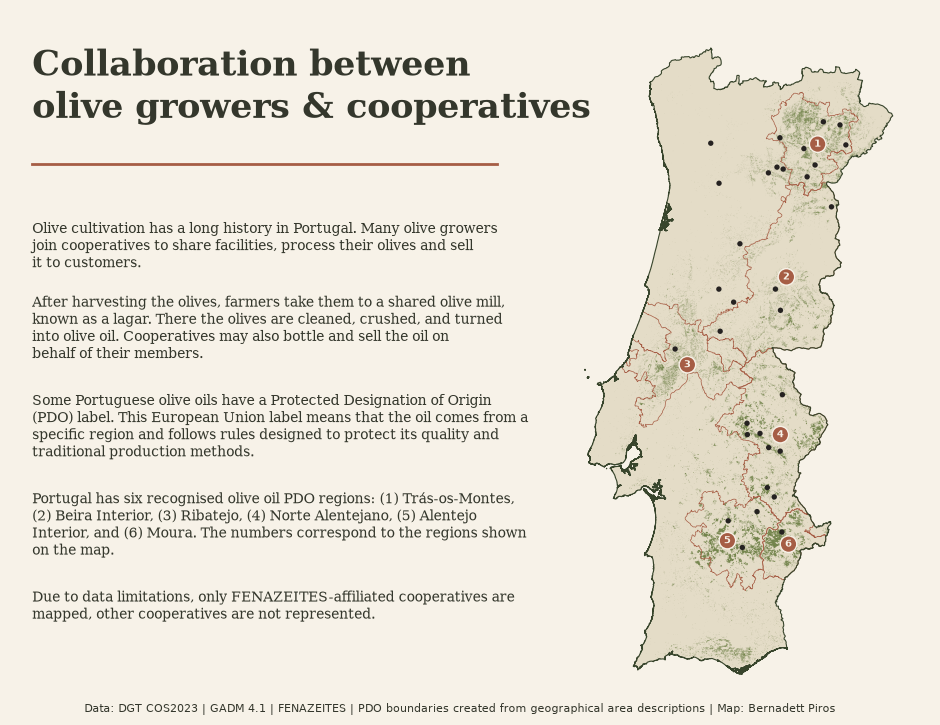

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 9), facecolor="#f7f2e8",
                               gridspec_kw={"width_ratios": [1.1, 1]})

###Left side
#Title
ax1.text(0.05, 0.95,
         "Collaboration between\nolive growers & cooperatives",  
         transform=ax1.transAxes, color="#34372C", size=25, weight="bold", fontfamily="serif", va="top")

# Head line
ax1.plot([0.05, 1.1], [0.78, 0.78], transform=ax1.transAxes, color="#A65D45", lw=2, clip_on=False)

y = 0.7

for paragraph in text_columns:

    wrapped = textwrap.fill(paragraph, width=70)

    ax1.text(0.05, y, wrapped, transform=ax1.transAxes, color="#34372C", fontfamily="serif", va="top",)

    lines = len(wrapped.split("\n"))
    y -= lines * 0.035

### Right side
# Portugal
portugal.plot(ax=ax2, facecolor="#E4DCC7", ec="none", zorder=1)

# Olive groves
olive_groves.plot(ax=ax2, color="#73844C", ec="none", rasterized=True, zorder=2)

# PDO 
pdo.boundary.plot(ax=ax2, color="#A65D45", lw=0.5, zorder=3)

# PDO annotation
for i, row in pdo.iterrows():    
    
    point = row.geometry.representative_point()

    ax2.text(point.x, point.y, str(i + 1), size=7, weight="bold", color="#f7f2e8", ha="center", va="center",
             bbox=dict(boxstyle="circle,pad=0.35", facecolor="#A65D45", ec="#f7f2e8", lw=1), zorder=10)

# Mainland boundary
portugal.boundary.plot(ax=ax2, color="#38452C", lw=0.8, zorder=4)

# Cooperatives
cooperatives.plot(ax=ax2, color="#252221", markersize=15, ec="none", zorder=6)

# Map extent
xmin, ymin, xmax, ymax = portugal.total_bounds
padding = 35000

ax2.set_xlim(xmin - padding, xmax + padding)
ax2.set_ylim(ymin - padding, ymax + padding)

ax2.set_aspect("equal")

# Hide axis
for ax in (ax1, ax2):
    ax.set_facecolor("#f7f2e8")
    ax.axis("off")

fig.text(0.5, 0.1,
         "Data: DGT COS2023 | GADM 4.1 | FENAZEITES | "
         "PDO boundaries created from geographical area descriptions | Map: Bernadett Piros",
         color="#34372C", size=8, ha="center")

plt.subplots_adjust(bottom=0.10)

plt.show()

# Save figure
#fig.savefig("cooperatives.png", bbox_inches="tight", pad_inches=0.2) 